75593
(11761, 51)
       BEGIN_DATE_TIME      STATE  MAGNITUDE DAMAGE_PROPERTY
17  24-OCT-23 08:59:00  WISCONSIN       1.00           0.00K
18  24-OCT-23 09:36:00  WISCONSIN       0.88           0.00K
22  24-OCT-23 09:07:00  WISCONSIN       1.75           0.00K
24  24-OCT-23 08:33:00  WISCONSIN       2.25           0.00K
25  06-AUG-23 20:47:00   ILLINOIS       1.25           0.00K
26  24-OCT-23 08:30:00  WISCONSIN       1.00           0.00K
30  06-AUG-23 20:49:00   ILLINOIS       1.00           0.00K
31  24-OCT-23 09:06:00  WISCONSIN       1.25           0.00K
35  06-AUG-23 18:20:00   ILLINOIS       1.00           0.00K
36  06-AUG-23 18:26:00   ILLINOIS       1.75           0.00K
Il y a 4968 événements grêle avec un montant de dommage renseigné (y compris 0), soit 42.2 % du total grêle. Dont 850 avec un dommage strictement positif, soit 7.2 % du total grêle.


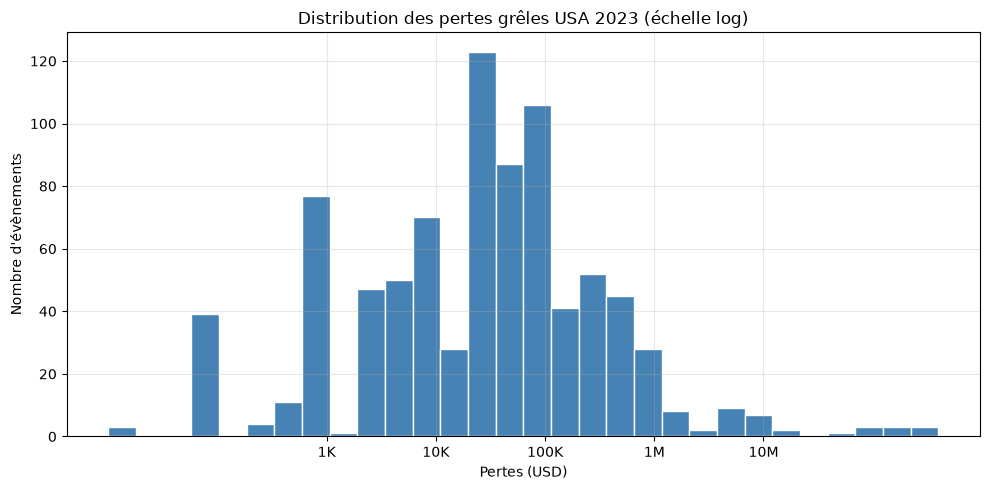

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#après r ' '
#dataset 2023 téléchargé depuis ncei.noaa.gov
chemin = "data/StormEvents_details-ftp_v1.0_d2023_c20260323.csv.gz"
# pd.read_csv, compression, low_memory
df_raw = pd.read_csv(chemin, compression = 'gzip', low_memory = False)
print(len(df_raw))
#que les lignes qui concernent la grêle
df_hail = df_raw[df_raw['EVENT_TYPE'] == 'Hail']
#pour afficher le nombre de lignes et colonnes
print(df_hail.shape)
print(df_hail[['BEGIN_DATE_TIME', 'STATE', 'MAGNITUDE', 'DAMAGE_PROPERTY']].head(10))
#!= différent de
df_hail_damage = df_hail[df_hail['DAMAGE_PROPERTY'] != '0.00K']
#.shape[0] pour le nombre de lignes, f"texte{}"
#fct pd.isna
def convertir_damage(valeur):
    if pd.isna(valeur):
        return 0
        
    valeur=str(valeur).strip()
#elif fait qu'a la première condition vrai, la fonction exécute son return sinon elle teste chaque condition
    if valeur.endswith('K'):
        return float(valeur[:-1])*1_000

    elif valeur.endswith('M'):
        return float(valeur[:-1])*1_000_000

    elif valeur.endswith('B'):
        return float(valeur[:-1])*1_000_000_000

    else:
        return float(valeur) if valeur else 0
        
df_hail_damage = df_hail_damage.copy()
#ajoute une colonne dmg usd a partir de dmg property et la fonction appliquée
df_hail_damage['DAMAGE_USD'] = df_hail_damage['DAMAGE_PROPERTY'].apply(convertir_damage)

df_hail_final = df_hail_damage[df_hail_damage['DAMAGE_USD'] > 0]
nb_positifs = (df_hail_damage['DAMAGE_USD'] > 0).sum()
print(f"Il y a {df_hail_damage.shape[0]} événements grêle avec un montant de dommage renseigné (y compris 0), soit {round(df_hail_damage.shape[0]/df_hail.shape[0]*100,1)} % du total grêle. Dont {nb_positifs} avec un dommage strictement positif, soit {round(nb_positifs/df_hail.shape[0]*100,1)} % du total grêle.")


plt.figure(figsize=(10,5))
plt.hist(np.log10(df_hail_final['DAMAGE_USD']), bins=30, color='steelblue', edgecolor='white')

plt.xticks([3,4,5,6,7],['1K','10K','100K','1M','10M'])
    
    
plt.title('Distribution des pertes grêles USA 2023 (échelle log)')

plt.xlabel('Pertes (USD)')

plt.ylabel("Nombre d'évènements")

plt.grid(True,alpha=0.3)

plt.tight_layout()
plt.show()

In [2]:
# Statistiques descriptives sur les pertes réelles
print(df_hail_final['DAMAGE_USD'].describe())

count    8.500000e+02
mean     2.590332e+06
std      2.398298e+07
min      1.000000e+01
25%      5.000000e+03
50%      3.000000e+04
75%      1.000000e+05
max      4.000000e+08
Name: DAMAGE_USD, dtype: float64


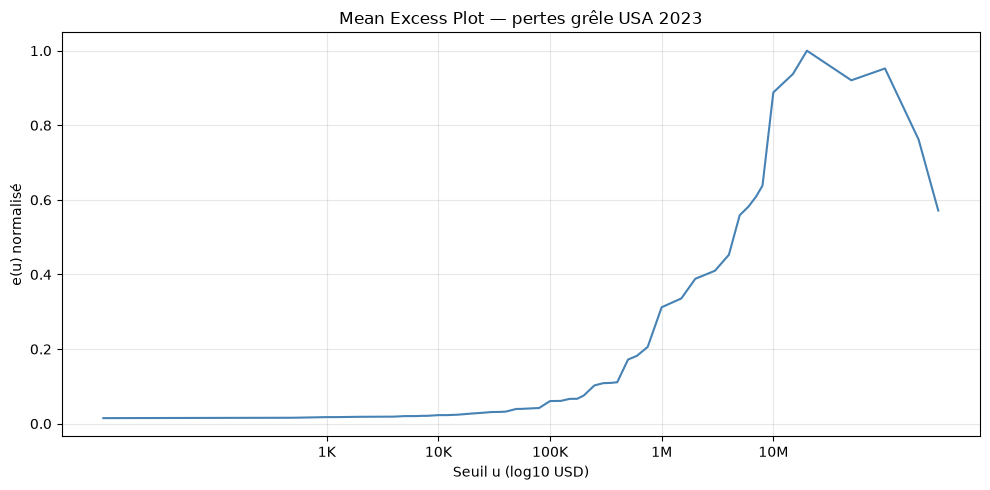

In [3]:
# e(u) = moyenne des excès au-dessus du seuil u). 
    
# on trie les données de manière croissante

data_sorted = np.sort(df_hail_final['DAMAGE_USD'].values)

# Pour chaque valeur u, on calcule e(u) = moyenne des excès au-dessus de u
seuils = data_sorted[:-1]  # tous les points sauf le dernier comme seuils car rien au dessus
mean_excess = [np.mean(data_sorted[data_sorted > u] - u) for u in seuils]

plt.figure(figsize=(10, 5))
plt.plot(np.log10(seuils), mean_excess / np.max(mean_excess), 
         color='steelblue', linewidth=1.5)
plt.title('Mean Excess Plot — pertes grêle USA 2023')
plt.xlabel('Seuil u (log10 USD)')
plt.ylabel('e(u) normalisé')
plt.xticks([3, 4, 5, 6, 7], ['1K', '10K', '100K', '1M', '10M'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# scipy = Scientific Python — librairie de calculs statistiques avancés
# stats = le module de scipy dédié aux distributions de probabilité
# from X import Y = on importe SEULEMENT le sous-module "stats" de scipy
# différent de "import scipy as sp" qui chargerait TOUT scipy (énorme, inutile)
# on n'a besoin que de "stats", donc on cible précisément ce module
from scipy import stats

# stats.lognorm.fit() trouve les paramètres de la loi lognormale
# qui correspondent le mieux à nos 850 valeurs de pertes
# "fit" = ajuster une courbe théorique sur des données réelles

# Une loi lognormale a 3 paramètres techniques :
# - shape (souvent noté sigma) = contrôle la dispersion/largeur de la courbe
# - loc = décale la distribution sur l'axe (translation)
# - scale = lié à la moyenne (exp(mu)), contrôle l'échelle

# floc=0 = on FIXE loc à 0 (on ne le laisse pas varier)
# Pourquoi ? Parce que des pertes ne peuvent pas être négatives —
# on force la distribution à commencer à 0, pas avant
#Cette fonction prend les 850 vraies valeurs et cherche : "quelles valeurs de shape et scale font que la courbe lognormale correspondante ressemble le plus possible à ces 850 points ?"
shape, loc, scale = stats.lognorm.fit(df_hail_final['DAMAGE_USD'], floc=0)

# :.3f = formate le nombre avec 3 décimales après la virgule
# f"texte {variable:.3f}" = f-string avec formatage de précision
print(f"Shape (sigma) : {shape:.3f}")

# :.0f = formate sans décimale (nombre entier)
print(f"Scale (exp(mu)) : {scale:.0f}")

#résultat: 
#Shape (sigma) = 2.637 — c'est élevé. Plus sigma est grand, plus la distribution est étalée/asymétrique. Pour comparaison, une lognormale "normale" a souvent sigma entre 0.5 et 1.5. Un sigma de 2.6 confirme une queue très épaisse — cohérent avec ton ratio moyenne/médiane de 86x.
#Scale (exp(mu)) = 25995 — proche de ta médiane (30000), c'est cohérent : pour une lognormale, scale représente la médiane théorique de la distribution.

Shape (sigma) : 2.637
Scale (exp(mu)) : 25995


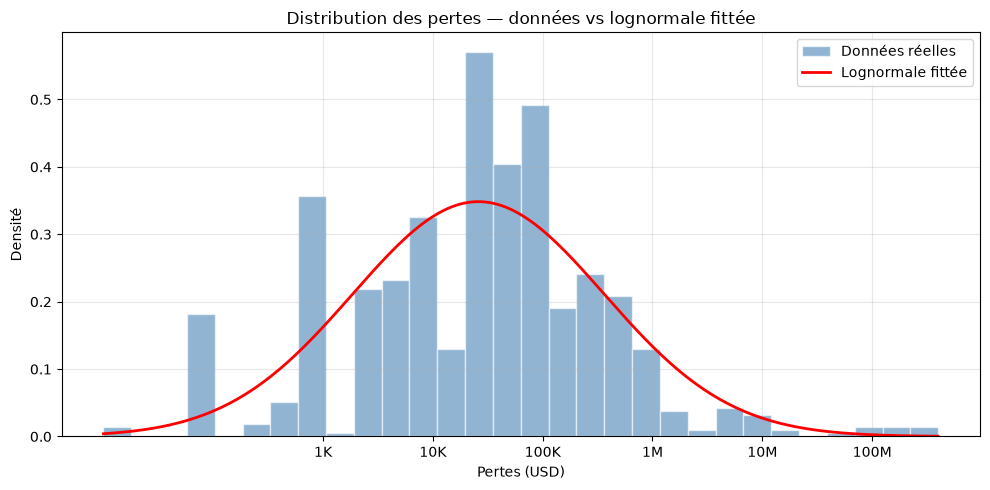

In [5]:
# génère 200 valeurs entre 10^1 (le min) et 10^8.6 (le max)
# soit entre 10 et ~400 000 000
# On crée une plage de valeurs de pertes de 10 à 400M, en échelle log
x = np.logspace(1, 8.6, 200)

# stats.lognorm.pdf() calcule la densité de probabilité théorique
# pour chaque valeur de x, selon notre lognormale fittée
#
y = stats.lognorm.pdf(x, shape, loc=0, scale=scale)

plt.figure(figsize=(10, 5))

# Histogramme des vraies données (normalisé en densité avec density=True)
# density=True transforme l'axe Y en densité de probabilité 
# au lieu de comptage brut — nécessaire pour comparer avec la courbe
plt.hist(np.log10(df_hail_final['DAMAGE_USD']), bins=30, density=True, 
         color='steelblue', edgecolor='white', alpha=0.6, label='Données réelles')

# On trace la courbe théorique — np.log10(x) pour rester sur la même échelle
plt.plot(np.log10(x), y * x * np.log(10), color='red', linewidth=2, label='Lognormale fittée')

plt.xticks([3, 4, 5, 6, 7, 8], ['1K', '10K', '100K', '1M', '10M', '100M'])
plt.title('Distribution des pertes — données vs lognormale fittée')
plt.xlabel('Pertes (USD)')
plt.ylabel('Densité')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# .ppf() = inverse de la fonction de répartition cumulée
# on lui donne une probabilité (0.99), elle renvoie la valeur de perte correspondante
#VaR 99% = "le montant de perte qui n'est dépassé que 1% du temps". Si tu te projettes sur 100 événements futurs, 99 seront sous ce seuil, 1 le dépassera.
var_99 = stats.lognorm.ppf(0.99, shape, loc=0, scale=scale)

print(f"VaR 99% : {var_99:,.0f} USD")

# Pour comparaison, calculons aussi la VaR 95% et la VaR 99.5%
var_95 = stats.lognorm.ppf(0.95, shape, loc=0, scale=scale)
var_995 = stats.lognorm.ppf(0.995, shape, loc=0, scale=scale)

print(f"VaR 95%   : {var_95:,.0f} USD")
print(f"VaR 99.5% : {var_995:,.0f} USD")

VaR 99% : 11,984,212 USD
VaR 95%   : 1,987,382 USD
VaR 99.5% : 23,135,132 USD


In [7]:
from scipy import stats

# Avec une seule année, notre meilleure estimation de lambda 
# est simplement le nombre d'événements observés
lambda_estime = df_hail_final.shape[0]

print(f"Lambda (fréquence annuelle estimée) : {lambda_estime}")

# La Poisson nous dit aussi : quelle est la probabilité d'avoir 
# exactement 900 événements l'année prochaine ?
proba_900 = stats.poisson.pmf(900, lambda_estime)
print(f"Probabilité d'avoir exactement 900 événements : {proba_900:.4f}")

Lambda (fréquence annuelle estimée) : 850
Probabilité d'avoir exactement 900 événements : 0.0031


In [8]:
# La prime pure = fréquence x sévérité moyenne
# C'est le montant moyen que l'assureur s'attend à payer par an

# Pour une lognormale, la moyenne théorique se calcule ainsi :
# moyenne = scale * exp(shape² / 2)

severite_moyenne = scale * np.exp(shape**2 / 2)
print(f"Sévérité moyenne (théorique) : {severite_moyenne:,.0f} USD")

prime_pure = lambda_estime * severite_moyenne
print(f"Prime pure annuelle : {prime_pure:,.0f} USD")

# Comparaison avec la moyenne empirique (directement sur les données)
print(f"Moyenne empirique observée : {df_hail_final['DAMAGE_USD'].mean():,.0f} USD")

Sévérité moyenne (théorique) : 840,083 USD
Prime pure annuelle : 714,070,678 USD
Moyenne empirique observée : 2,590,332 USD


In [9]:
# Fit d'une Pareto généralisée sur les mêmes données
shape_pareto, loc_pareto, scale_pareto = stats.genpareto.fit(df_hail_final['DAMAGE_USD'], floc=0)

print(f"Shape Pareto : {shape_pareto:.3f}")
print(f"Scale Pareto : {scale_pareto:,.0f}")

# Moyenne théorique de la Pareto généralisée
# Attention : si shape >= 1, la moyenne est infinie (queue trop épaisse)
if shape_pareto < 1:
    moyenne_pareto = scale_pareto / (1 - shape_pareto)
    print(f"Moyenne théorique Pareto : {moyenne_pareto:,.0f} USD")
else:
    print("Moyenne théorique Pareto : infinie (shape >= 1)")

# VaR 99% selon Pareto, pour comparer avec la lognormale (11.98M)
var_99_pareto = stats.genpareto.ppf(0.99, shape_pareto, loc=0, scale=scale_pareto)
print(f"VaR 99% Pareto : {var_99_pareto:,.0f} USD")
var995_pareto = stats.genpareto.ppf(0.995, shape_pareto, loc=0, scale=scale_pareto)
print(f"VaR 99.5% Pareto : {var995_pareto:,.0f} USD")

Shape Pareto : 1.982
Scale Pareto : 14,845
Moyenne théorique Pareto : infinie (shape >= 1)
VaR 99% Pareto : 69,044,738 USD
VaR 99.5% Pareto : 272,849,741 USD


In [10]:
# Impossible de calculer une prime pure stable
# La moyenne théorique diverge — pas de formule fermée utilisable
#prime_pure_pareto = "indéfinie (shape ≥ 1)"

In [11]:
# Fit Weibull (version "exponentielle" généralisée, weibull_min en scipy)
shape_weib, loc_weib, scale_weib = stats.weibull_min.fit(df_hail_final['DAMAGE_USD'], floc=0)

print(f"Shape Weibull : {shape_weib:.3f}")
print(f"Scale Weibull : {scale_weib:,.0f}")

# VaR 99% Weibull
var_99_weib = stats.weibull_min.ppf(0.99, shape_weib, loc=0, scale=scale_weib)
print(f"VaR 99% Weibull : {var_99_weib:,.0f} USD")

from scipy.special import gamma

# Moyenne théorique Weibull = scale × Γ(1 + 1/k)
# Γ = fonction gamma — généralisation de la factorielle aux réels
moyenne_weib = scale_weib * gamma(1 + 1/shape_weib)
prime_pure_weib = lambda_estime * moyenne_weib
print(f"Sévérité moyenne Weibull : {moyenne_weib:,.0f} USD")
print(f"Prime pure Weibull : {prime_pure_weib:,.0f} USD")

Shape Weibull : 0.345
Scale Weibull : 98,368
VaR 99% Weibull : 8,179,841 USD
Sévérité moyenne Weibull : 517,900 USD
Prime pure Weibull : 440,215,405 USD


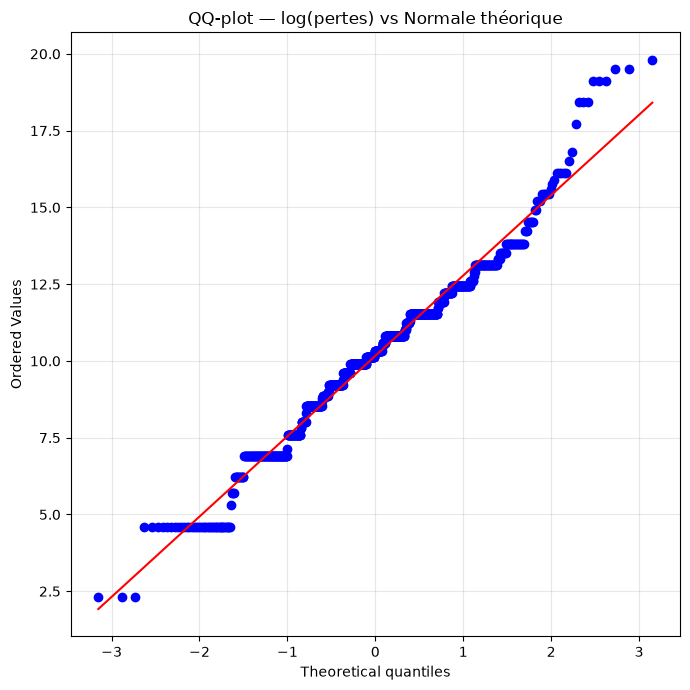

In [12]:
# QQ-plot : compare les quantiles empiriques vs théoriques lognormaux
fig, ax = plt.subplots(figsize=(7, 7))

# génère les quantiles théoriques de notre lognormale fittée
stats.probplot(np.log(df_hail_final['DAMAGE_USD']), 
               dist='norm', 
               plot=ax)

ax.set_title('QQ-plot — log(pertes) vs Normale théorique')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# --- Comparaison AIC ---
# AIC = 2*k - 2*log-vraisemblance
# k = nombre de paramètres (2 pour chacune de nos 3 lois)
# Plus l'AIC est BAS, meilleur est le fit

k = 2  # shape + scale pour les 3 lois (loc fixé à 0)

loglik_lognorm = np.sum(stats.lognorm.logpdf(df_hail_final['DAMAGE_USD'], shape, loc=0, scale=scale))
loglik_pareto = np.sum(stats.genpareto.logpdf(df_hail_final['DAMAGE_USD'], shape_pareto, loc=0, scale=scale_pareto))
loglik_weib = np.sum(stats.weibull_min.logpdf(df_hail_final['DAMAGE_USD'], shape_weib, loc=0, scale=scale_weib))

aic_lognorm = 2*k - 2*loglik_lognorm
aic_pareto = 2*k - 2*loglik_pareto
aic_weib = 2*k - 2*loglik_weib

print(f"\nAIC Lognormale : {aic_lognorm:,.1f}")
print(f"AIC Pareto     : {aic_pareto:,.1f}")
print(f"AIC Weibull    : {aic_weib:,.1f}")


AIC Lognormale : 21,345.9
AIC Pareto     : 21,403.3
AIC Weibull    : 21,574.1


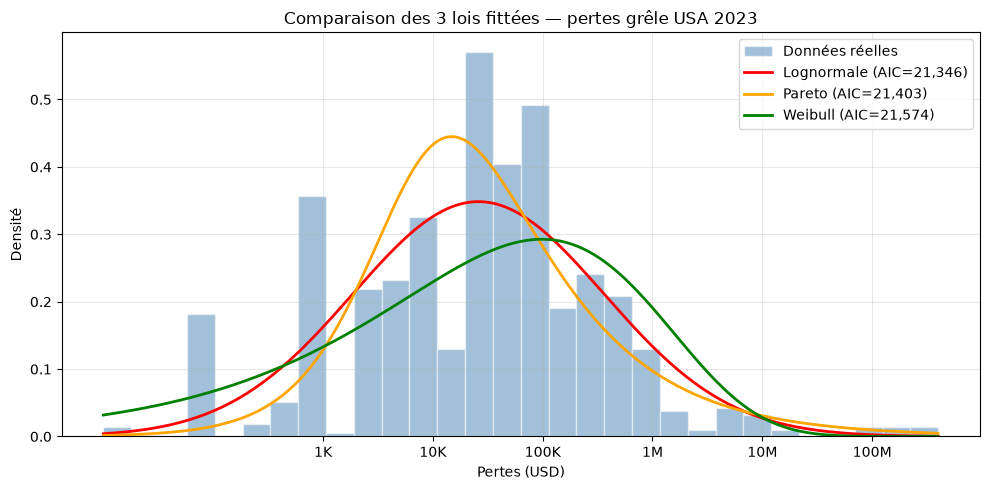

In [14]:
x = np.logspace(1, 8.6, 200)

# Densités des 3 lois (avec correction pour l'axe log)
y_lognorm = stats.lognorm.pdf(x, shape, loc=0, scale=scale) * x * np.log(10)
y_pareto = stats.genpareto.pdf(x, shape_pareto, loc=0, scale=scale_pareto) * x * np.log(10)
y_weib = stats.weibull_min.pdf(x, shape_weib, loc=0, scale=scale_weib) * x * np.log(10)

plt.figure(figsize=(10, 5))

# Histogramme données réelles
plt.hist(np.log10(df_hail_final['DAMAGE_USD']), bins=30, density=True,
         color='steelblue', edgecolor='white', alpha=0.5, label='Données réelles')

# 3 courbes fittées
plt.plot(np.log10(x), y_lognorm, color='red', linewidth=2, label=f'Lognormale (AIC={aic_lognorm:,.0f})')
plt.plot(np.log10(x), y_pareto, color='orange', linewidth=2, label=f'Pareto (AIC={aic_pareto:,.0f})')
plt.plot(np.log10(x), y_weib, color='green', linewidth=2, label=f'Weibull (AIC={aic_weib:,.0f})')

plt.xticks([3, 4, 5, 6, 7, 8], ['1K', '10K', '100K', '1M', '10M', '100M'])
plt.title('Comparaison des 3 lois fittées — pertes grêle USA 2023')
plt.xlabel('Pertes (USD)')
plt.ylabel('Densité')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

 ## Conclusions Niveau 2

- Loi retenue : **Lognormale** (AIC = 21,346 ; MEP globalement croissant)
- Shape σ = 2.637 : queue très épaisse
- VaR 99 % par événement : lognormale 11.98M USD | Pareto (stress) 69.04M USD
- Fréquence annuelle λ = 850 (1 an de données : limite identifiée)
- Prime pure théorique 714M USD vs empirique 2.2Md USD : instabilité due à 1 an de données
- QQ-plot : bon ajustement sur le corps, déviation en queue, Pareto retenue pour le stress test

In [15]:
#on charge les 30 années d'un coup pour pouvoir les comparer entre elles
# le contrôle des colonnes vérifie que tous les fichiers ont la même structure
import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# le * remplace n'importe quel texte : on prend tous les fichiers StormEvents du dossier data
#glob sert à lister les fichiers du dossier data
fichiers = sorted(glob.glob("data/StormEvents_details-ftp_v1.0_d*_c*.csv.gz"))
print(len(fichiers))
print(fichiers[0])
print(fichiers[-1])

tous = []                   # liste vide : on y mettra un tableau par année
colonnes_ref = None          # servira à vérifier que tous les fichiers ont les mêmes colonnes

for f in fichiers:
    d = pd.read_csv(f, compression='gzip', low_memory=False)

    # contrôle de structure : on compare les colonnes à celles du premier fichier
    if colonnes_ref is None:
        colonnes_ref = list(d.columns)
    elif list(d.columns) != colonnes_ref:
        print("Colonnes différentes dans", f)

    tous.append(d)

df_all = pd.concat(tous, ignore_index=True)
print(df_all.shape)

30
data\StormEvents_details-ftp_v1.0_d1996_c20260323.csv.gz
data\StormEvents_details-ftp_v1.0_d2025_c20260819.csv.gz
(1780730, 51)


In [16]:
# on liste les noms des colonnes pour savoir exactement ce que contient NOAA
print(df_all.shape)                  # nombre de lignes et de colonnes (51 colonnes)
print(df_all.columns.tolist())       # tous les noms de colonnes


(1780730, 51)
['BEGIN_YEARMONTH', 'BEGIN_DAY', 'BEGIN_TIME', 'END_YEARMONTH', 'END_DAY', 'END_TIME', 'EPISODE_ID', 'EVENT_ID', 'STATE', 'STATE_FIPS', 'YEAR', 'MONTH_NAME', 'EVENT_TYPE', 'CZ_TYPE', 'CZ_FIPS', 'CZ_NAME', 'WFO', 'BEGIN_DATE_TIME', 'CZ_TIMEZONE', 'END_DATE_TIME', 'INJURIES_DIRECT', 'INJURIES_INDIRECT', 'DEATHS_DIRECT', 'DEATHS_INDIRECT', 'DAMAGE_PROPERTY', 'DAMAGE_CROPS', 'SOURCE', 'MAGNITUDE', 'MAGNITUDE_TYPE', 'FLOOD_CAUSE', 'CATEGORY', 'TOR_F_SCALE', 'TOR_LENGTH', 'TOR_WIDTH', 'TOR_OTHER_WFO', 'TOR_OTHER_CZ_STATE', 'TOR_OTHER_CZ_FIPS', 'TOR_OTHER_CZ_NAME', 'BEGIN_RANGE', 'BEGIN_AZIMUTH', 'BEGIN_LOCATION', 'END_RANGE', 'END_AZIMUTH', 'END_LOCATION', 'BEGIN_LAT', 'BEGIN_LON', 'END_LAT', 'END_LON', 'EPISODE_NARRATIVE', 'EVENT_NARRATIVE', 'DATA_SOURCE']


In [17]:
#si certains fichiers écrivaient la grêle autrement (ex : "Thunderstorm Wind/Hail"), filtrer sur 'Hail' ferait perdre des événements sans qu'on le voie
#on regarde que chaque data_set n'a pas d'autres noms pour parler de grêles.
print(df_all['EVENT_TYPE'].value_counts())
#on compte le nombres de lignes grêles par année (chaque dataset)
df_all_hail = df_all[df_all['EVENT_TYPE'] == 'Hail']
df_all_hail_each_year = df_all_hail['YEAR'].value_counts().sort_index()
print(df_all_hail_each_year) #par année
print(len(df_all_hail)) #au total

EVENT_TYPE
Thunderstorm Wind             450605
Hail                          337858
Flash Flood                   110265
High Wind                      95793
Winter Storm                   90242
Winter Weather                 83262
Drought                        81383
Heavy Snow                     75186
Flood                          70041
Marine Thunderstorm Wind       43020
Tornado                        42775
Heat                           34898
Heavy Rain                     31507
Strong Wind                    28076
Excessive Heat                 21179
Lightning                      18169
Extreme Cold/Wind Chill        18114
Cold/Wind Chill                18010
Dense Fog                      17428
Blizzard                       16977
Frost/Freeze                   15139
Ice Storm                      12494
High Surf                      10633
Funnel Cloud                    9937
Wildfire                        9326
Tropical Storm                  7146
Waterspout                 

In [18]:
# même fonction qu'au niveau 2, avec une protection en plus :
# si après avoir retiré K, M ou B il ne reste aucun nombre (un "K" seul faisait planter la conversion (ValueError)), on renvoie 0
def convertir_damage(valeur):
    if pd.isna(valeur):
        return 0

    valeur = str(valeur).strip()

    # on isole le nombre : on retire la dernière lettre si c'est K, M ou B
    if valeur[-1:] in ('K', 'M', 'B'):
        nombre = valeur[:-1]
    else:
        nombre = valeur

    # montant illisible (ex : "K" tout seul) -> on le traite comme inconnu
    if nombre == '':
        return 0
    
    if valeur.endswith('K'):
        return float(nombre) * 1_000

    elif valeur.endswith('M'):
        return float(nombre) * 1_000_000

    elif valeur.endswith('B'):
        return float(nombre) * 1_000_000_000

    else:
        return float(nombre)

In [19]:
#avant de modéliser, on vérifie que la déclaration des dommages est comparable d'une année à l'autre
# on compte par année : toutes les lignes grêle, celles avec dommage > 0, et les "petits montants" (< 1 000 USD)
# pour voir si leur part change dans le temps
# la fréquence qu'on veut estimer = nombre d'événements avec un dommage déclaré par an
# elle n'est fiable que si la déclaration des dommages est comparable d'une année à l'autre
# on filtre la grêle sur les 30 années ; .copy() pour pouvoir ajouter une colonne sans avertissement
df_hail = df_all[df_all['EVENT_TYPE'] == 'Hail'].copy()

# ajoute une colonne DAMAGE_USD à partir de DAMAGE_PROPERTY et de la fonction appliquée
df_hail['DAMAGE_USD'] = df_hail['DAMAGE_PROPERTY'].apply(convertir_damage)

# groupby('YEAR') = on fait un paquet de lignes par année
# .size() = on compte les lignes de chaque paquet
nb_total = df_hail.groupby('YEAR').size()

# lignes avec un dommage strictement positif, puis on les compte par année
df_positifs = df_hail[df_hail['DAMAGE_USD'] > 0]
nb_positif = df_positifs.groupby('YEAR').size()

# parmi elles, celles avec un dommage inférieur à 1 000 USD (les "petits montants")
df_petits = df_positifs[df_positifs['DAMAGE_USD'] < 1000]
nb_petits = df_petits.groupby('YEAR').size()

# on assemble les trois séries dans un tableau ; fillna(0) met 0 si une année n'a aucun petit montant
par_annee = pd.DataFrame({'nb_total': nb_total, 'nb_positif': nb_positif, 'nb_petits': nb_petits}).fillna(0)

# pourcentages arrondis à 1 décimale
par_annee['part_positif_%'] = (par_annee['nb_positif'] / par_annee['nb_total'] * 100).round(1)
par_annee['part_petits_%'] = (par_annee['nb_petits'] / par_annee['nb_positif'] * 100).round(1)

print(par_annee)

      nb_total  nb_positif  nb_petits  part_positif_%  part_petits_%
YEAR                                                                
1996     10826         942        152             8.7           16.1
1997      8612         963        138            11.2           14.3
1998     12561        1436        225            11.4           15.7
1999     10146         908        157             8.9           17.3
2000     11296        1175        127            10.4           10.8
2001     12224        1303        176            10.7           13.5
2002     12540        1225        138             9.8           11.3
2003     13915        1564        195            11.2           12.5
2004     13164        1335        145            10.1           10.9
2005     13808        1232        149             8.9           12.1
2006     16656        1697         66            10.2            3.9
2007     12712        1040         11             8.2            1.1
2008     17768        1749        

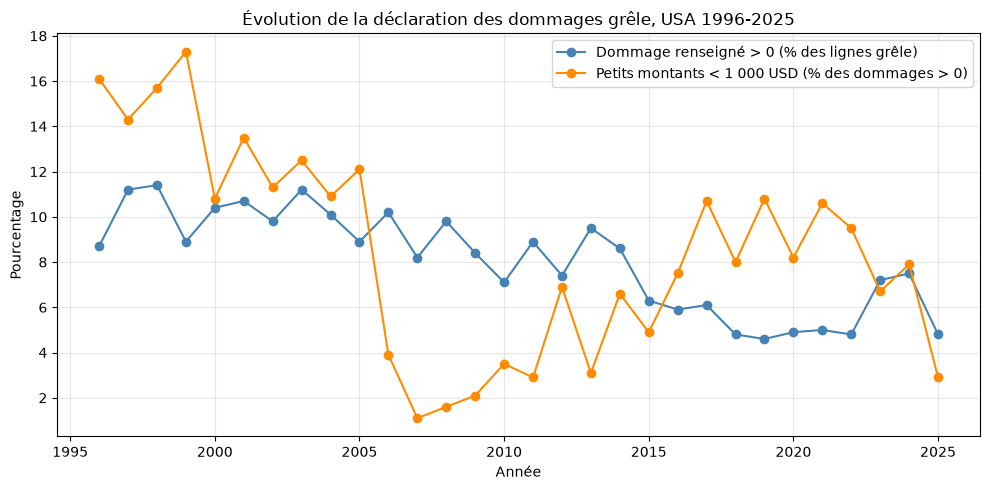

In [20]:
#visualisation graphique pour voir s'il y a des changements bizarres (y en a :( )
#si elle change beaucoup, la fréquence mesurée dépend de la façon de déclarer et pas seulement du risque
plt.figure(figsize=(10,5))

plt.plot(par_annee.index, par_annee['part_positif_%'], marker='o', color='steelblue', label='Dommage renseigné > 0 (% des lignes grêle)')
plt.plot(par_annee.index, par_annee['part_petits_%'], marker='o', color='darkorange', label='Petits montants < 1 000 USD (% des dommages > 0)')

plt.title('Évolution de la déclaration des dommages grêle, USA 1996-2025')
plt.xlabel('Année')
plt.ylabel('Pourcentage')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# # on teste si la taille de la grêle donne une fréquence plus stable que le montant.
# on regarde si elle est renseignée chaque année, et si sa moyenne et le nombre de grosses grêles (>= 1 pouce) restent stables
# combien de lignes ont une taille renseignée, par année ?
nb_taille = df_hail[df_hail['MAGNITUDE'].notna()].groupby('YEAR').size()

# combien de lignes avec une grêle d'au moins 1 pouce (environ 2,5 cm) ?
nb_gros = df_hail[df_hail['MAGNITUDE'] >= 1.0].groupby('YEAR').size()

# taille moyenne par année
taille_moy = df_hail.groupby('YEAR')['MAGNITUDE'].mean().round(2)

tab_taille = pd.DataFrame({'nb_total': nb_total, 'nb_taille': nb_taille, 'nb_gros': nb_gros, 'taille_moy': taille_moy}).fillna(0)
tab_taille['part_taille_%'] = (tab_taille['nb_taille'] / tab_taille['nb_total'] * 100).round(1)

print(tab_taille)

      nb_total  nb_taille  nb_gros  taille_moy  part_taille_%
YEAR                                                         
1996     10826      10779     5466        1.15           99.6
1997      8612       8594     3976        1.08           99.8
1998     12561      12557     6177        1.13          100.0
1999     10146      10142     4938        1.11          100.0
2000     11296      11281     5428        1.09           99.9
2001     12224      12212     5591        1.07           99.9
2002     12540      12539     5705        1.07          100.0
2003     13915      13915     6476        1.09          100.0
2004     13164      13164     6123        1.07          100.0
2005     13808      13808     6652        1.07          100.0
2006     16656      16656     7782        1.07          100.0
2007     12712      12712     5889        1.05          100.0
2008     17768      17768     8453        1.07          100.0
2009     13313      13313     7503        1.12          100.0
2010    

In [22]:
#Pour l'instant on va tout de même construire la fréquence sur les montants de dommages. On verra si on utilisera la magnitude.


#EPISODE_ID = identifiant NOAA de l'épisode : une même tempête a souvent plusieurs lignes (une par comté)
#Erreur du NIVEAU 2, une ligne NOAA = un segment de comté, pas une tempête. on avait considéré une ligne = un évènement. On corrige.
# on vérifie d'abord combien de lignes n'ont pas d'identifiant

print(df_hail['EPISODE_ID'].isna().sum())

# combien de lignes grêle par épisode ? (on regroupe par année ET par épisode pour éviter tout mélange)
lignes_par_episode = df_hail.groupby(['YEAR', 'EPISODE_ID']).size()
print(lignes_par_episode.describe())
print(len(lignes_par_episode))   # nombre total d'épisodes grêle sur 30 ans

0
count    105447.000000
mean          3.204055
std           5.806222
min           1.000000
25%           1.000000
50%           1.000000
75%           3.000000
max         160.000000
dtype: float64
105447


In [23]:
#on regarde les plus gros épisodes pour vérifier qu'un épisode correspond bien à une vraie tempête
# (et pas à plusieurs jours ou plusieurs États regroupés par erreur)

# les 5 plus gros épisodes en nombre de lignes
print(lignes_par_episode.sort_values(ascending=False).head(5))

# idxmax donne ici un couple (année, épisode)
annee_max, ep_max = lignes_par_episode.idxmax()
gros = df_hail[(df_hail['YEAR'] == annee_max) & (df_hail['EPISODE_ID'] == ep_max)]

print(annee_max, ep_max)
print(gros[['BEGIN_DATE_TIME', 'STATE', 'CZ_NAME', 'MAGNITUDE', 'DAMAGE_USD']].head(15))

# combien d'États et combien de jours différents dans ce seul épisode ?
print(gros['STATE'].nunique(), "États")
print(gros['BEGIN_DATE_TIME'].str[:9].nunique(), "jours différents")

YEAR  EPISODE_ID
2023  178154.0      160
      181487.0      159
1999  2406299.0     146
1998  2078644.0     124
2024  190994.0      120
dtype: int64
2023 178154.0
            BEGIN_DATE_TIME     STATE    CZ_NAME  MAGNITUDE  DAMAGE_USD
1563370  19-APR-23 16:18:00  OKLAHOMA      GRADY       1.75         0.0
1563371  19-APR-23 16:20:00  OKLAHOMA      CADDO       1.25         0.0
1563372  19-APR-23 17:18:00  OKLAHOMA  CLEVELAND       1.00         0.0
1563373  19-APR-23 17:28:00  OKLAHOMA  CLEVELAND       1.00         0.0
1563374  19-APR-23 16:06:00  OKLAHOMA      GRADY       1.25         0.0
1563375  19-APR-23 16:08:00  OKLAHOMA   COMANCHE       1.00         0.0
1563378  19-APR-23 17:22:00  OKLAHOMA   OKLAHOMA       1.25         0.0
1563379  19-APR-23 18:12:00  OKLAHOMA   OKLAHOMA       2.00         0.0
1564191  19-APR-23 19:10:00  OKLAHOMA  CLEVELAND       2.00         0.0
1564192  19-APR-23 18:41:00  OKLAHOMA  CLEVELAND       1.00         0.0
1564193  19-APR-23 20:00:00  OKLAHOMA  CLEVE

In [24]:
#on construit le tableau d'une ligne par tempête, avec dommage_total = somme des lignes de l'épisode
# et on vérifie sur tous les épisodes (pas seulement le plus gros) combien durent plus d'un jour ou touchent plusieurs États

# on extrait le jour de chaque ligne : les 9 premiers caractères de BEGIN_DATE_TIME (ex : 19-APR-23)
df_hail['JOUR'] = df_hail['BEGIN_DATE_TIME'].str[:9]

# un tableau avec une ligne par épisode (= par tempête)
# nunique = nombre de valeurs différentes ; sum = somme des dommages de toutes les lignes de l'épisode
episodes = df_hail.groupby(['YEAR', 'EPISODE_ID']).agg(
    nb_lignes=('EVENT_ID', 'size'),
    nb_etats=('STATE', 'nunique'),
    nb_jours=('JOUR', 'nunique'),
    dommage_total=('DAMAGE_USD', 'sum')
)

print(episodes[['nb_lignes', 'nb_etats', 'nb_jours']].describe())

# part des épisodes qui s'étendent sur plusieurs jours, puis sur plusieurs États
print((episodes['nb_jours'] > 1).mean() * 100, "% des épisodes sur plus d'un jour")
print((episodes['nb_etats'] > 1).mean() * 100, "% des épisodes sur plus d'un État")

           nb_lignes  nb_etats       nb_jours
count  105447.000000  105447.0  105447.000000
mean        3.204055       1.0       1.033685
std         5.806222       0.0       0.224961
min         1.000000       1.0       1.000000
25%         1.000000       1.0       1.000000
50%         1.000000       1.0       1.000000
75%         3.000000       1.0       1.000000
max       160.000000       1.0      15.000000
2.927537056530769 % des épisodes sur plus d'un jour
0.0 % des épisodes sur plus d'un État


In [25]:
#fréquence = nombre de tempêtes avec un dommage déclaré par année ; c'est ce qu'on observe vraiment
# un épisode "avec dommage" = dommage total strictement positif


# un épisode "avec dommage" = dommage total strictement positif
episodes['avec_dommage'] = episodes['dommage_total'] > 0

# nombre de tempêtes avec dommage, par année
freq_par_annee = episodes.groupby('YEAR')['avec_dommage'].sum()
print(freq_par_annee)

YEAR
1996    942
1997    653
1998    614
1999    389
2000    500
2001    419
2002    452
2003    524
2004    446
2005    557
2006    560
2007    388
2008    506
2009    398
2010    300
2011    436
2012    375
2013    321
2014    260
2015    245
2016    229
2017    257
2018    176
2019    196
2020    146
2021    151
2022    148
2023    228
2024    199
2025    165
Name: avec_dommage, dtype: int64


count    10741.000000
mean         1.007914
std          0.318330
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         27.000000
Name: nb_lignes, dtype: float64
1996 -2025 : 30 ans | moyenne 372.7 | variance 34205.7 | variance/moyenne 91.8
2007 -2025 : 19 ans | moyenne 269.7 | variance 11512.3 | variance/moyenne 42.7
2015 -2025 : 11 ans | moyenne 194.5 | variance 1641.1 | variance/moyenne 8.4
2018 -2025 : 8 ans | moyenne 176.1 | variance 866.1 | variance/moyenne 4.9


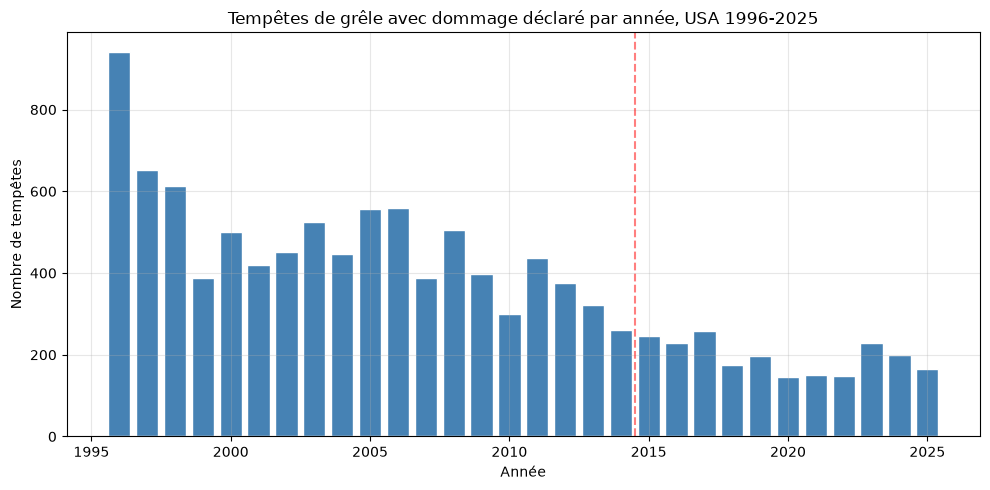

In [26]:
#en 1996, pourquoi y a 942 tempêtes = 942 lignes avec dommage ? il devrait y en avoir moins
# on compare aussi la moyenne et la variance de la fréquence selon la fenêtre donc entre 1996-2025, 2007-2025, 2015-2025, 2018-2025: la Poisson suppose variance = moyenne



# 1996 : les épisodes regroupent-ils vraiment les lignes cette année-là ?
print(episodes.loc[1996, 'nb_lignes'].describe())

# moyenne et variance de la fréquence annuelle selon la fenêtre de calibration
# .var() = variance ; si variance/moyenne est bien supérieure à 1, la Poisson ne convient pas
for debut in [1996, 2007, 2015, 2018]:
    serie = freq_par_annee[freq_par_annee.index >= debut]
    print(debut, "-2025 :", len(serie), "ans | moyenne", round(serie.mean(), 1),
          "| variance", round(serie.var(), 1),
          "| variance/moyenne", round(serie.var() / serie.mean(), 1))

# graphique de la fréquence annuelle
plt.figure(figsize=(10, 5))
plt.bar(freq_par_annee.index, freq_par_annee.values, color='steelblue', edgecolor='white')
plt.axvline(2014.5, color='red', linestyle='--', alpha=0.5)   # début de la fenêtre 2015-2025
plt.title('Tempêtes de grêle avec dommage déclaré par année, USA 1996-2025')
plt.xlabel('Année')
plt.ylabel('Nombre de tempêtes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
#après 1996, on cherche d'autres années où le regroupement en épisodes ne fonctionne pas ou change
#1) pour chaque année : moyenne de lignes par épisode
# proche de 1 = les lignes ne sont pas regroupées (comme en 1996) ; on cherche d'autres années du même type
lignes_moy = episodes.groupby('YEAR')['nb_lignes'].mean().round(2)
print(lignes_moy)

YEAR
1996    1.01
1997    1.98
1998    2.31
1999    2.59
2000    2.46
2001    2.58
2002    2.55
2003    2.39
2004    2.55
2005    2.50
2006    2.40
2007    4.42
2008    5.22
2009    4.61
2010    4.43
2011    5.49
2012    4.81
2013    4.30
2014    4.52
2015    4.37
2016    4.39
2017    4.90
2018    4.07
2019    4.06
2020    4.40
2021    4.14
2022    4.22
2023    5.29
2024    4.92
2025    5.29
Name: nb_lignes, dtype: float64


In [28]:
# on garde 2015-2025 comme fenêtre principale. Elle est un peu moins homogène que 2018-2025 (variance/moyenne 8,4 contre 4,9)
# mais elle donne 11 années au lieu de 8, donc plus de tempêtes pour estimer la sévérité (2 140)
# les fenêtres qui commencent en 1996 ou 2007 varient beaucoup plus (variance/moyenne 91,8 et 42,7) : on les écarte
#2 ) tempêtes avec dommage déclaré, fenêtre 2015-2025 (1996 exclue : épisodes non regroupés)
DEBUT_FENETRE = 2015

# reset_index remet YEAR et EPISODE_ID en colonnes normales
df_storms = episodes[episodes['avec_dommage']].reset_index()
df_storms = df_storms[df_storms['YEAR'] >= DEBUT_FENETRE]

print(len(df_storms), "tempêtes avec dommage")   # tu dois trouver 2 140

# mêmes statistiques descriptives qu'au niveau 2, mais par tempête
print(df_storms['dommage_total'].describe())
print("Ratio moyenne/médiane :", round(df_storms['dommage_total'].mean() / df_storms['dommage_total'].median(), 1))

2140 tempêtes avec dommage
count    2.140000e+03
mean     5.373001e+06
std      7.237100e+07
min      1.000000e+01
25%      3.000000e+03
50%      2.000000e+04
75%      1.050000e+05
max      2.300000e+09
Name: dommage_total, dtype: float64
Ratio moyenne/médiane : 268.7


In [29]:
#la moyenne par tempête est très au-dessus de la médiane : on mesure le poids des plus grosses tempêtes dans le total
#les 10 plus grosses tempêtes par dommage total
top = df_storms.sort_values('dommage_total', ascending=False).head(10)
print(top[['YEAR', 'EPISODE_ID', 'nb_lignes', 'dommage_total']])

# poids de ces tempêtes dans le total
total = df_storms['dommage_total'].sum()
print("Part de la plus grosse tempête :", round(top['dommage_total'].iloc[0] / total * 100, 1), "%")
print("Part des 10 plus grosses :", round(top['dommage_total'].sum() / total * 100, 1), "%")

       YEAR  EPISODE_ID  nb_lignes  dommage_total
9566   2017    114300.0         36   2.300000e+09
9313   2016    104003.0         35   1.360000e+09
10684  2023    180703.0         20   1.300200e+09
9327   2016    104185.0         52   7.501990e+08
9322   2016    104103.0         30   6.015370e+08
10797  2023    185807.0         65   6.000020e+08
9090   2015     94194.0          9   5.000600e+08
10337  2021    157639.0         30   5.000000e+08
10302  2021    156822.0         40   4.625950e+08
9352   2016    104657.0         68   3.444500e+08
Part de la plus grosse tempête : 20.0 %
Part des 10 plus grosses : 75.8 %


In [30]:
#si le même montant était recopié sur chaque ligne d'une tempête, sommer par épisode le compterait plusieurs fois
# on vérifie sur les 10 plus grosses combien de lignes portent un dommage et quelle part pèse la ligne la plus chère
# pour chaque grosse tempête : combien de lignes ont un dommage > 0, et quelle part du total porte la ligne la plus chère ?

#un montant de 2,3 milliards sur une seule tempête pourrait être une erreur de saisie : on lit les lignes et la narration NOAA
#on ouvre la plus grosse tempête : quelles lignes portent le montant ?
annee_top = top.iloc[0]['YEAR']
ep_top = top.iloc[0]['EPISODE_ID']
gros = df_hail[(df_hail['YEAR'] == annee_top) & (df_hail['EPISODE_ID'] == ep_top)]

print(gros[['BEGIN_DATE_TIME', 'STATE', 'CZ_NAME', 'MAGNITUDE', 'DAMAGE_USD']].sort_values('DAMAGE_USD', ascending=False).head(10))

# la narration de la ligne la plus chère : que dit NOAA ?
print(gros.loc[gros['DAMAGE_USD'].idxmax(), 'EVENT_NARRATIVE'])


            BEGIN_DATE_TIME     STATE    CZ_NAME  MAGNITUDE    DAMAGE_USD
1231901  08-MAY-17 14:05:00  COLORADO  JEFFERSON       2.75  2.300000e+09
1231397  08-MAY-17 13:30:00  COLORADO  JEFFERSON       1.00  0.000000e+00
1231399  08-MAY-17 13:48:00  COLORADO  JEFFERSON       1.25  0.000000e+00
1231398  08-MAY-17 13:40:00  COLORADO  JEFFERSON       1.25  0.000000e+00
1231400  08-MAY-17 13:50:00  COLORADO  JEFFERSON       2.00  0.000000e+00
1231401  08-MAY-17 13:52:00  COLORADO  JEFFERSON       1.00  0.000000e+00
1231403  08-MAY-17 13:52:00  COLORADO  JEFFERSON       2.00  0.000000e+00
1231402  08-MAY-17 13:52:00  COLORADO  JEFFERSON       1.75  0.000000e+00
1231450  08-MAY-17 14:05:00  COLORADO     DENVER       1.00  0.000000e+00
1231451  08-MAY-17 14:05:00  COLORADO  JEFFERSON       1.75  0.000000e+00
The estimated damage is for the entire episode.


In [31]:
# pour chaque grosse tempête : combien de lignes ont un dommage > 0, et quelle part du total porte la ligne la plus chère ?
# ERREUR NIVEAU 2 : le dommage d'une tempête est parfois sur une seule ligne -> dommage_total = somme des lignes de l'épisode
for i, ligne in top.iterrows():
    lignes = df_hail[(df_hail['YEAR'] == ligne['YEAR']) & (df_hail['EPISODE_ID'] == ligne['EPISODE_ID'])]
    print(int(ligne['YEAR']), "| lignes avec dommage > 0 :", (lignes['DAMAGE_USD'] > 0).sum(),
          "| ligne max / total :", round(lignes['DAMAGE_USD'].max() / lignes['DAMAGE_USD'].sum(), 2))

2017 | lignes avec dommage > 0 : 1 | ligne max / total : 1.0
2016 | lignes avec dommage > 0 : 1 | ligne max / total : 1.0
2023 | lignes avec dommage > 0 : 8 | ligne max / total : 0.31
2016 | lignes avec dommage > 0 : 16 | ligne max / total : 0.2
2016 | lignes avec dommage > 0 : 17 | ligne max / total : 0.33
2023 | lignes avec dommage > 0 : 3 | ligne max / total : 0.5
2015 | lignes avec dommage > 0 : 5 | ligne max / total : 0.6
2021 | lignes avec dommage > 0 : 18 | ligne max / total : 0.08
2021 | lignes avec dommage > 0 : 14 | ligne max / total : 0.13
2016 | lignes avec dommage > 0 : 47 | ligne max / total : 0.29


In [32]:
# ERREUR NIVEAU 2 : lambda = 850 lignes avec dommage en 2023 ; par tempête, 2023 en compte 228
#par tempête, la part de dommages renseignés reste entre 8 % et 15 % : plus stable que par ligne
#par ligne, la part de dommages renseignés baissait ; on refait le contrôle par tempête
# pour savoir si la fréquence est instable à cause de la déclaration ou de la façon de compter
nb_tempetes = episodes.groupby('YEAR').size()
part_tempetes = (freq_par_annee / nb_tempetes * 100).round(1)

tab_tempetes = pd.DataFrame({'nb_tempetes': nb_tempetes, 'nb_avec_dommage': freq_par_annee, 'part_%': part_tempetes})
print(tab_tempetes)

      nb_tempetes  nb_avec_dommage  part_%
YEAR                                      
1996        10741              942     8.8
1997         4344              653    15.0
1998         5433              614    11.3
1999         3919              389     9.9
2000         4583              500    10.9
2001         4738              419     8.8
2002         4909              452     9.2
2003         5820              524     9.0
2004         5161              446     8.6
2005         5533              557    10.1
2006         6952              560     8.1
2007         2877              388    13.5
2008         3402              506    14.9
2009         2887              398    13.8
2010         2462              300    12.2
2011         3156              436    13.8
2012         2781              375    13.5
2013         2240              321    14.3
2014         2202              260    11.8
2015         2149              245    11.4
2016         2145              229    10.7
2017       

In [33]:
#le montant est instable mais la taille de la grêle est renseignée partout : on regarde, par tempête, combien ont une grêle >= 1 pouce
# et quelle part de ces grosses tempêtes a un dommage déclaré (piste pour une fréquence plus stable)
# taille maximale de grêle observée dans chaque épisode
#taille maximale de grêle observée dans chaque épisode
episodes['taille_max'] = df_hail.groupby(['YEAR', 'EPISODE_ID'])['MAGNITUDE'].max()
episodes['gros'] = episodes['taille_max'] >= 1.0       # tempête avec grêle d'au moins 1 pouce

nb_gros = episodes.groupby('YEAR')['gros'].sum()
nb_gros_dommage = episodes[episodes['gros']].groupby('YEAR')['avec_dommage'].sum()

tab_gros = pd.DataFrame({'nb_tempetes': nb_tempetes, 'nb_gros': nb_gros,
                         'nb_avec_dommage': freq_par_annee, 'nb_gros_dommage': nb_gros_dommage})
tab_gros['part_gros_%'] = (tab_gros['nb_gros'] / tab_gros['nb_tempetes'] * 100).round(1)
tab_gros['dommage_parmi_gros_%'] = (tab_gros['nb_gros_dommage'] / tab_gros['nb_gros'] * 100).round(1)

print(tab_gros)

      nb_tempetes  nb_gros  nb_avec_dommage  nb_gros_dommage  part_gros_%  \
YEAR                                                                        
1996        10741     5407              942              606         50.3   
1997         4344     2167              653              414         49.9   
1998         5433     2927              614              565         53.9   
1999         3919     2116              389              329         54.0   
2000         4583     2509              500              438         54.7   
2001         4738     2394              419              353         50.5   
2002         4909     2483              452              372         50.6   
2003         5820     2955              524              441         50.8   
2004         5161     2596              446              385         50.3   
2005         5533     2776              557              425         50.2   
2006         6952     3463              560              502         49.8   

Perte min : 10 USD
Perte max : 2,300,000,000 USD


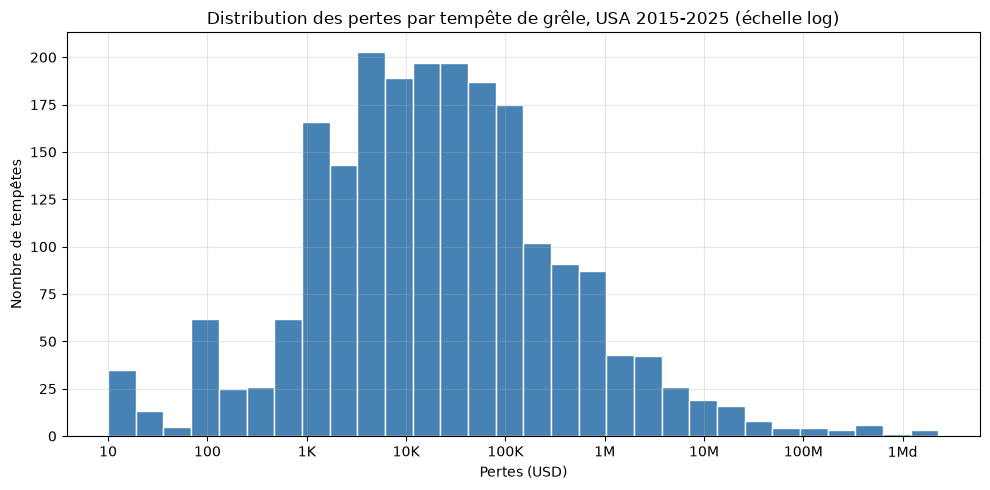

In [34]:
#comme au niveau 2, on regarde la forme de la distribution des pertes avant de choisir une loi
# bornes des pertes par tempête : sert à choisir l'échelle des axes
print(f"Perte min : {df_storms['dommage_total'].min():,.0f} USD")
print(f"Perte max : {df_storms['dommage_total'].max():,.0f} USD")

plt.figure(figsize=(10, 5))
plt.hist(np.log10(df_storms['dommage_total']), bins=30, color='steelblue', edgecolor='white')

# les repères de l'axe : 10^1 = 10 USD jusqu'à 10^9 = 1 milliard
plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9], ['10', '100', '1K', '10K', '100K', '1M', '10M', '100M', '1Md'])

plt.title('Distribution des pertes par tempête de grêle, USA 2015-2025 (échelle log)')
plt.xlabel('Pertes (USD)')
plt.ylabel('Nombre de tempêtes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

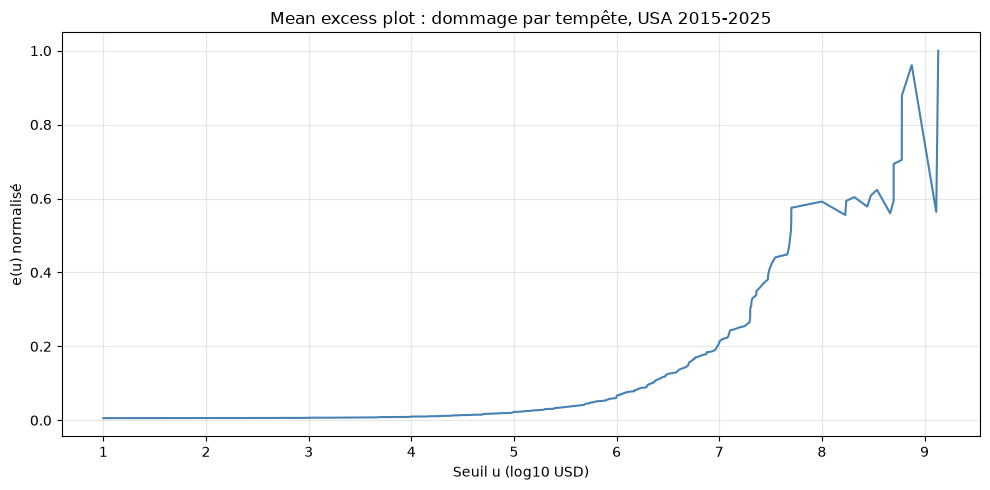

In [35]:
# mean excess plot, comme au niveau 2 : e(u) = moyenne des excès au-dessus du seuil u
# lecture : courbe qui monte = queue lourde ; plate = exponentielle ; qui descend = queue légère

# on trie les montants par tempête de manière croissante
data_sorted = np.sort(df_storms['dommage_total'].values)

# tous les points sauf le dernier comme seuils, car il n'y a rien au-dessus du dernier
seuils = data_sorted[:-1]

# pour chaque seuil u : moyenne de (montant - u) pour les montants au-dessus de u
mean_excess = [np.mean(data_sorted[data_sorted > u] - u) for u in seuils]

plt.figure(figsize=(10, 5))
plt.plot(np.log10(seuils), mean_excess / np.max(mean_excess), color='steelblue')

plt.title('Mean excess plot : dommage par tempête, USA 2015-2025')
plt.xlabel('Seuil u (log10 USD)')
plt.ylabel('e(u) normalisé')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
from scipy import stats

# on commence par la lognormale, comme au niveau 2

# stats.lognorm.fit() trouve les paramètres de la loi lognormale
# qui correspondent le mieux à nos montants par tempête
# floc=0 : on fixe la localisation à 0 (une perte ne peut pas être négative)
shape, loc, scale = stats.lognorm.fit(df_storms['dommage_total'], floc=0)

print(f"Shape (sigma) : {shape:.3f}")
print(f"Scale (exp(mu)) : {scale:.0f}")

Shape (sigma) : 2.955
Scale (exp(mu)) : 19921


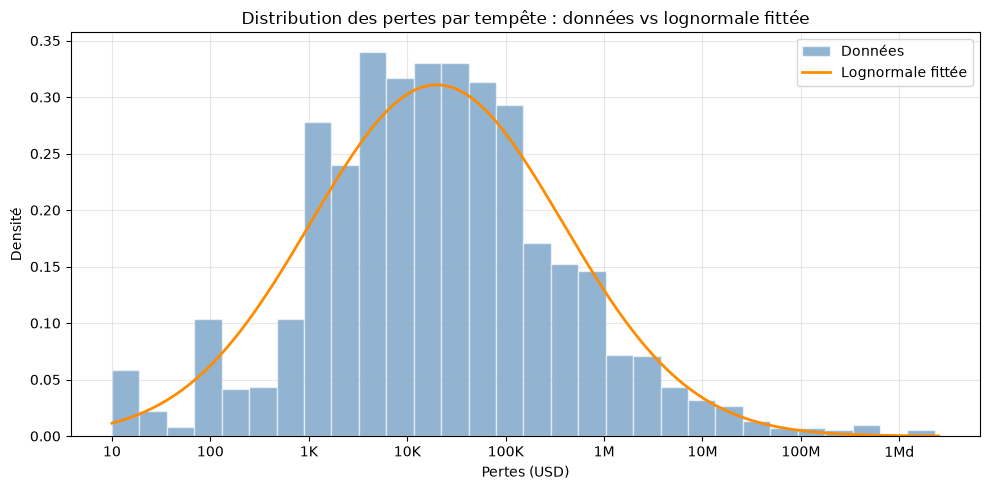

In [37]:
# plage de pertes de 10 USD à environ 2,5 Md (min et max affichés plus haut : 10 USD et 2,3 Md), en échelle log
x = np.logspace(1, 9.4, 200)

# densité théorique de la lognormale, avec la correction pour l'axe log10
# (on trace en log10, donc on multiplie la densité par x * ln(10))
y = stats.lognorm.pdf(x, shape, loc=0, scale=scale) * x * np.log(10)

plt.figure(figsize=(10, 5))

# histogramme des vraies données, normalisé en densité avec density=True
plt.hist(np.log10(df_storms['dommage_total']), bins=30, density=True,
         color='steelblue', edgecolor='white', alpha=0.6, label='Données')

plt.plot(np.log10(x), y, color='darkorange', linewidth=2, label='Lognormale fittée')

plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9], ['10', '100', '1K', '10K', '100K', '1M', '10M', '100M', '1Md'])
plt.title('Distribution des pertes par tempête : données vs lognormale fittée')
plt.xlabel('Pertes (USD)')
plt.ylabel('Densité')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# attention : c'est la VaR d'UNE tempête, pas de la perte annuelle
# .ppf() = inverse de la fonction de répartition cumulée
# on lui donne une probabilité (0.99), elle renvoie la valeur de perte correspondante
# VaR 99% = "le montant de perte qui n'est dépassé que 1% du temps" : sur 100 tempêtes avec dommage, 99 sont sous ce seuil
var_95 = stats.lognorm.ppf(0.95, shape, loc=0, scale=scale)
var_99 = stats.lognorm.ppf(0.99, shape, loc=0, scale=scale)
var_995 = stats.lognorm.ppf(0.995, shape, loc=0, scale=scale)

print(f"VaR 95%   : {var_95:,.0f} USD")
print(f"VaR 99%   : {var_99:,.0f} USD")
print(f"VaR 99.5% : {var_995:,.0f} USD")

VaR 95%   : 2,570,181 USD
VaR 99%   : 19,250,910 USD
VaR 99.5% : 40,233,118 USD


In [39]:
# ERREUR NIVEAU 2 : une seule année, impossible de tester la Poisson
# ici variance/moyenne = 8,4 > 1 : la Poisson ne convient pas, on retient la binomiale négative
# fréquence annuelle sur la fenêtre de calibration (DEBUT_FENETRE = 2015 défini plus haut)
serie = freq_par_annee[freq_par_annee.index >= DEBUT_FENETRE]

m = serie.mean()      # moyenne annuelle
v = serie.var()       # variance annuelle
lambda_estime = m
print(f"Lambda (tempêtes avec dommage par an) : {lambda_estime:.1f}")
print(f"Variance : {v:.1f}  |  variance / moyenne : {v / m:.1f}")

# Poisson (niveau 2) : variance = moyenne
# Binomiale négative : variance > moyenne
# paramètres de la binomiale négative par la méthode des moments :
p_nb = m / v
n_nb = m * p_nb / (1 - p_nb)
print(f"Binomiale négative : n = {n_nb:.1f}, p = {p_nb:.3f}")

# si la Poisson convenait, une année comme la plus forte observée serait quasi impossible
# on calcule donc la probabilité d'une telle année sous chaque loi, calibrée sur la même moyenne
annee_max = serie.idxmax()
k_max = serie.max()
print(f"Année la plus forte : {annee_max} avec {k_max} tempêtes")

# .sf(k-1) = P(N >= k) : probabilité d'avoir au moins autant de tempêtes que cette année-là
print("Poisson            : P(N >= k_max) =", stats.poisson.sf(k_max - 1, m))
print("Binomiale négative : P(N >= k_max) =", stats.nbinom.sf(k_max - 1, n_nb, p_nb))

Lambda (tempêtes avec dommage par an) : 194.5
Variance : 1641.1  |  variance / moyenne : 8.4
Binomiale négative : n = 26.2, p = 0.119
Année la plus forte : 2017 avec 257 tempêtes
Poisson            : P(N >= k_max) = 1.0970442720841505e-05
Binomiale négative : P(N >= k_max) = 0.07177930114008628


In [40]:
# La prime pure = fréquence x sévérité moyenne
# C'est le montant moyen que l'assureur s'attend à payer par an

# Pour une lognormale, la moyenne théorique se calcule ainsi :
# moyenne = scale * exp(shape² / 2)
severite_moyenne = scale * np.exp(shape**2 / 2)
print(f"Sévérité moyenne (théorique) : {severite_moyenne:,.0f} USD")

# on garde la même formule fréquence x sévérité : elle reste valable avec la binomiale négative
# (l'espérance du nombre de tempêtes est lambda_estime dans les deux cas)
prime_pure = lambda_estime * severite_moyenne
print(f"Prime pure annuelle : {prime_pure:,.0f} USD")

# Comparaison avec ce qu'on observe vraiment : total des dommages / nombre d'années de la fenêtre
nb_annees = df_storms['YEAR'].nunique()
total_empirique_par_an = df_storms['dommage_total'].sum() / nb_annees
print(f"Moyenne empirique observée par an : {total_empirique_par_an:,.0f} USD")
# rapport > 1 : le modèle sous-estime la moyenne observée (≈ 3,1 au niveau 2 : 2,2 Md / 714 M)
print(f"Rapport empirique / modèle : {total_empirique_par_an / prime_pure:.1f}")

Sévérité moyenne (théorique) : 1,566,741 USD
Prime pure annuelle : 304,802,302 USD
Moyenne empirique observée par an : 1,045,292,897 USD
Rapport empirique / modèle : 3.4


In [41]:
# on reproduit les 3 lois du niveau 2 sur les tempêtes 2015-2025 : lognormale (fait), Pareto, Weibull
shape_pareto, loc_pareto, scale_pareto = stats.genpareto.fit(df_storms['dommage_total'], floc=0)

print(f"Shape Pareto : {shape_pareto:.3f}")
print(f"Scale Pareto : {scale_pareto:,.0f}")

# Moyenne théorique de la Pareto généralisée
# Attention : si shape >= 1, la moyenne est infinie (queue trop épaisse)
if shape_pareto < 1:
    moyenne_pareto = scale_pareto / (1 - shape_pareto)
    print(f"Moyenne théorique Pareto : {moyenne_pareto:,.0f} USD")
else:
    print("Moyenne théorique Pareto : infinie (shape >= 1)")

# VaR 99% de la Pareto
var_99_pareto = stats.genpareto.ppf(0.99, shape_pareto, loc=0, scale=scale_pareto)
print(f"VaR 99% Pareto : {var_99_pareto:,.0f} USD")

Shape Pareto : 2.455
Scale Pareto : 7,900
Moyenne théorique Pareto : infinie (shape >= 1)
VaR 99% Pareto : 261,103,874 USD


In [42]:
from scipy.special import gamma

# Weibull : 3e candidate, comme au niveau 2
shape_weib, loc_weib, scale_weib = stats.weibull_min.fit(df_storms['dommage_total'], floc=0)

print(f"Shape Weibull : {shape_weib:.3f}")
print(f"Scale Weibull : {scale_weib:,.0f}")

# VaR 99% Weibull
var_99_weib = stats.weibull_min.ppf(0.99, shape_weib, loc=0, scale=scale_weib)
print(f"VaR 99% Weibull : {var_99_weib:,.0f} USD")

# Moyenne théorique Weibull = scale × Γ(1 + 1/k), Γ = fonction gamma
moyenne_weib = scale_weib * gamma(1 + 1 / shape_weib)
print(f"Sévérité moyenne Weibull : {moyenne_weib:,.0f} USD")

prime_pure_weib = lambda_estime * moyenne_weib
print(f"Prime pure Weibull : {prime_pure_weib:,.0f} USD")

Shape Weibull : 0.309
Scale Weibull : 89,605
VaR 99% Weibull : 12,556,975 USD
Sévérité moyenne Weibull : 729,184 USD
Prime pure Weibull : 141,859,459 USD


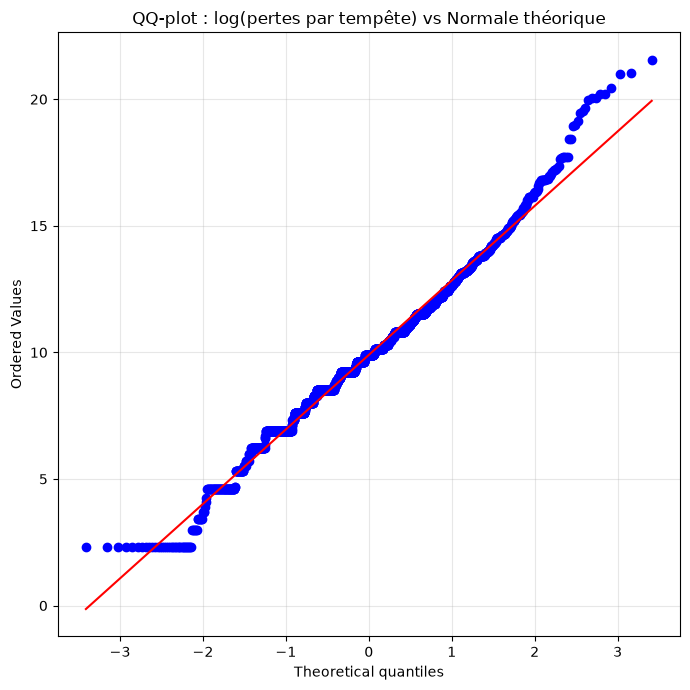

In [43]:
# QQ-plot : on compare les quantiles de log(pertes) à ceux d'une loi normale
# (si les pertes sont lognormales, leur log est normal : les points doivent suivre la droite)
# écart des points à la droite = écart à la lognormale, surtout dans les queues
fig, ax = plt.subplots(figsize=(7, 7))

stats.probplot(np.log(df_storms['dommage_total']), dist='norm', plot=ax)

ax.set_title('QQ-plot : log(pertes par tempête) vs Normale théorique')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
# --- Comparaison AIC ---
# AIC = 2*k - 2*log-vraisemblance ; plus l'AIC est BAS, meilleur est le fit
# k = 2 paramètres pour chacune des 3 lois (loc fixé à 0)
k = 2
# AIC Pareto : fittée sur tout l'échantillon (erreur niveau 2), comparaison à relativiser
donnees = df_storms['dommage_total']

loglik_lognorm = np.sum(stats.lognorm.logpdf(donnees, shape, loc=0, scale=scale))
loglik_pareto = np.sum(stats.genpareto.logpdf(donnees, shape_pareto, loc=0, scale=scale_pareto))
loglik_weib = np.sum(stats.weibull_min.logpdf(donnees, shape_weib, loc=0, scale=scale_weib))

aic_lognorm = 2 * k - 2 * loglik_lognorm
aic_pareto = 2 * k - 2 * loglik_pareto
aic_weib = 2 * k - 2 * loglik_weib

print(f"AIC Lognormale : {aic_lognorm:,.1f}")
print(f"AIC Pareto     : {aic_pareto:,.1f}")
print(f"AIC Weibull    : {aic_weib:,.1f}")

AIC Lognormale : 53,083.8
AIC Pareto     : 53,200.9
AIC Weibull    : 53,669.1


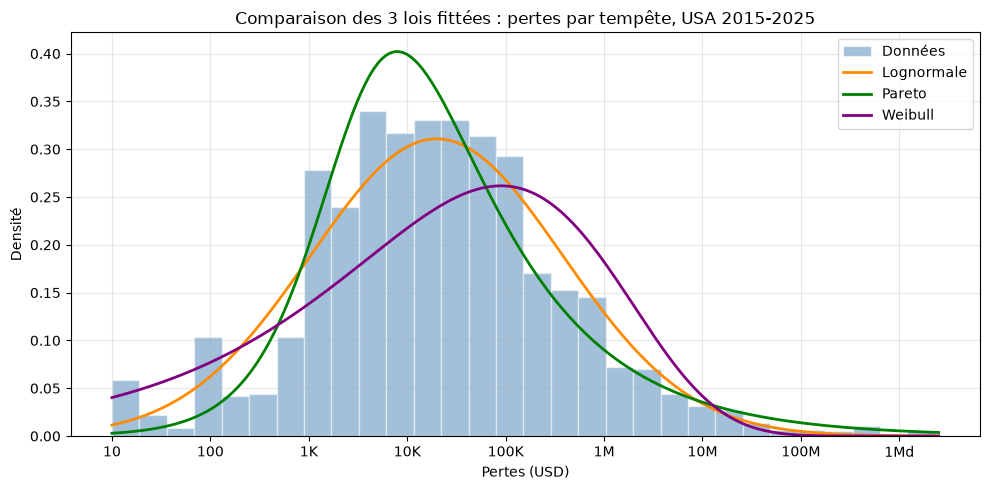

In [45]:
# même grille de pertes que pour la lognormale seule

# densités des 3 lois (avec la correction pour l'axe log10)
y_lognorm = stats.lognorm.pdf(x, shape, loc=0, scale=scale) * x * np.log(10)
y_pareto = stats.genpareto.pdf(x, shape_pareto, loc=0, scale=scale_pareto) * x * np.log(10)
y_weib = stats.weibull_min.pdf(x, shape_weib, loc=0, scale=scale_weib) * x * np.log(10)

plt.figure(figsize=(10, 5))

plt.hist(np.log10(df_storms['dommage_total']), bins=30, density=True,
         color='steelblue', edgecolor='white', alpha=0.5, label='Données')

plt.plot(np.log10(x), y_lognorm, color='darkorange', linewidth=2, label='Lognormale')
plt.plot(np.log10(x), y_pareto, color='green', linewidth=2, label='Pareto')
plt.plot(np.log10(x), y_weib, color='purple', linewidth=2, label='Weibull')

plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9], ['10', '100', '1K', '10K', '100K', '1M', '10M', '100M', '1Md'])
plt.title('Comparaison des 3 lois fittées : pertes par tempête, USA 2015-2025')
plt.xlabel('Pertes (USD)')
plt.ylabel('Densité')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
# la lognormale a le meilleur AIC mais ne reproduit pas la moyenne observée (ratio 3,4)
# et la Pareto fittée sur tout l'échantillon (erreur niveau 2) donne une moyenne infinie
#on essaie cette fois POT (peaks over threshold) = on ne fitte la queue qu'au-dessus d'un seuil u
# le mean excess plot (plus haut) sert aussi de repère pour le seuil : on teste plusieurs quantiles élevés

niveaux = [0.80, 0.90, 0.95, 0.975]

for q in niveaux:
    u_cand = df_storms['dommage_total'].quantile(q)
    nb_exces = (df_storms['dommage_total'] > u_cand).sum()
    print(f"quantile {q:.1%} : u = {u_cand:,.0f} USD, {nb_exces} excès")

quantile 80.0% : u = 195,000 USD, 426 excès
quantile 90.0% : u = 810,800 USD, 214 excès
quantile 95.0% : u = 2,500,000 USD, 106 excès
quantile 97.5% : u = 10,000,000 USD, 53 excès


In [47]:
# on fitte une GPD sur les excès (montant - u) pour chaque seuil candidat
# différence avec le niveau 2 : on fitte sur (montant - u), pas sur le montant brut
# si la forme est stable d'un seuil à l'autre, la queue est bien décrite par une GPD
for q in niveaux:
    u_cand = df_storms['dommage_total'].quantile(q)
    exces_cand = df_storms['dommage_total'][df_storms['dommage_total'] > u_cand] - u_cand
    forme, _, echelle = stats.genpareto.fit(exces_cand, floc=0)
    print(f"quantile {q:.1%} : forme = {forme:.3f}, échelle = {echelle:,.0f}, {len(exces_cand)} excès")

quantile 80.0% : forme = 1.767, échelle = 426,548, 426 excès
quantile 90.0% : forme = 1.872, échelle = 1,231,190, 214 excès
quantile 95.0% : forme = 1.659, échelle = 5,812,058, 106 excès
quantile 97.5% : forme = 1.598, échelle = 19,502,033, 53 excès


In [48]:
# seuil retenu : quantile 90 % (214 excès) ; la forme varie peu d'un seuil à l'autre (1,6 à 1,9).
# bootstrap : on rééchantillonne les excès avec remise et on refitte la GPD, pour mesurer l'incertitude de la forme
# si tout l'intervalle est au-dessus de 1, la moyenne de la GPD est infinie
u = df_storms['dommage_total'].quantile(0.90)
exces = (df_storms['dommage_total'][df_storms['dommage_total'] > u] - u).values

# GPD retenue : fit sur les excès au-dessus de u ; forme_u et echelle_u servent dans toute la suite
forme_u, _, echelle_u = stats.genpareto.fit(exces, floc=0)
print(f"GPD retenue : forme = {forme_u:.3f}, échelle = {echelle_u:,.0f}")

# graine fixée : le résultat est reproductible.
rng = np.random.default_rng(42)
formes = []
for _ in range(1000):
    echantillon = rng.choice(exces, size=len(exces), replace=True)
    f, _, _ = stats.genpareto.fit(echantillon, floc=0)
    formes.append(f)

print(f"forme : médiane = {np.median(formes):.3f}, IC 95 % = [{np.percentile(formes, 2.5):.3f} ; {np.percentile(formes, 97.5):.3f}]")

GPD retenue : forme = 1.872, échelle = 1,231,190
forme : médiane = 1.862, IC 95 % = [1.547 ; 2.193]


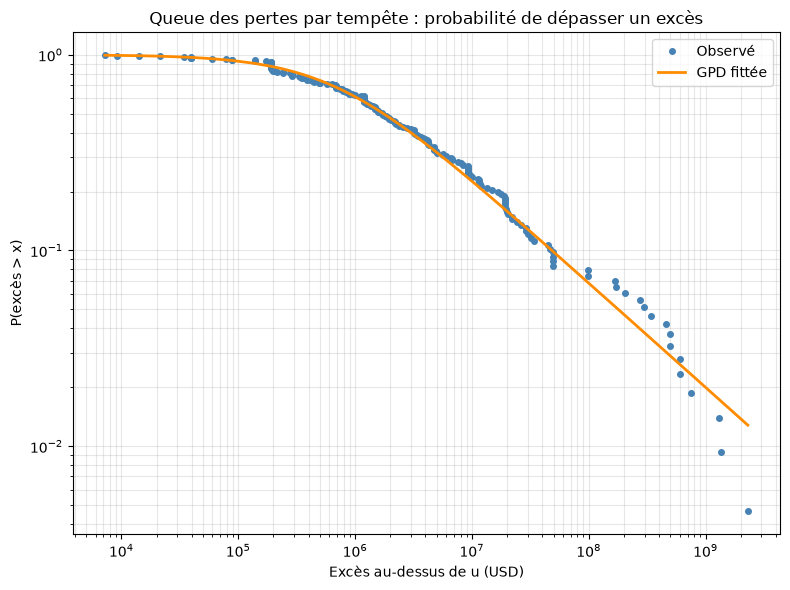

In [49]:
# probabilité de dépasser chaque excès : empirique vs GPD fittée
# lecture : points sur la courbe = la GPD décrit bien la queue ; à droite, on regarde l'écart sur les plus grosses tempêtes
# (les marches viennent des montants arrondis)
exces_tries = np.sort(exces)
n = len(exces_tries)
# probabilité empirique de dépasser chaque excès : 1 - rang/(n+1).
proba_emp = 1 - np.arange(1, n + 1) / (n + 1)

forme_u, _, echelle_u = stats.genpareto.fit(exces, floc=0)
proba_gpd = stats.genpareto.sf(exces_tries, forme_u, loc=0, scale=echelle_u)

plt.figure(figsize=(8, 6))
plt.loglog(exces_tries, proba_emp, 'o', markersize=4, color='steelblue', label='Observé')
plt.loglog(exces_tries, proba_gpd, '-', color='darkorange', linewidth=2, label='GPD fittée')
plt.title("Queue des pertes par tempête : probabilité de dépasser un excès")
plt.xlabel("Excès au-dessus de u (USD)")
plt.ylabel("P(excès > x)")
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

In [50]:
# la forme est > 1 : moyenne infinie. On plafonne la perte d'une tempête à C pour obtenir une moyenne finie
# le plafond de 1 Md est sous le maximum observé (2,3 Md) : il couperait une tempête réelle
# espérance de l'excès plafonné : E[min(Y, C - u)] = intégrale de P(Y > y) de 0 à C - u
from scipy.integrate import quad

plafonds = [1e9, 2.5e9, 5e9, 1e10]   # perte maximale supposée par tempête (USD)

for C in plafonds:
    limite = C - u
    esperance, _ = quad(lambda y: stats.genpareto.sf(y, forme_u, loc=0, scale=echelle_u), 0, limite)
    print(f"plafond {C:,.0f} USD : E[excès plafonné] = {esperance:,.0f} USD")

plafond 1,000,000,000 USD : E[excès plafonné] = 41,461,846 USD
plafond 2,500,000,000 USD : E[excès plafonné] = 64,295,991 USD
plafond 5,000,000,000 USD : E[excès plafonné] = 89,344,989 USD
plafond 10,000,000,000 USD : E[excès plafonné] = 123,942,299 USD


In [51]:
# modèle assemblé : corps = données sous u ; queue = GPD plafonnée au-dessus de u
# sévérité moyenne = part du corps + P(queue) x (u + excès moyen plafonné)
# choisi 2,5 Md comme plafond de base, comme premier plafond testé au-dessus du maximum observé (2,3 Md)
# rapport empirique / modèle : comparable au 3,4 de la lognormale
n_tempetes = len(df_storms)
p_u = (df_storms['dommage_total'] > u).mean()                       # part de tempêtes dans la queue
# contrib_corps : somme des pertes sous u divisée par le nombre total de tempêtes
contrib_corps = df_storms['dommage_total'][df_storms['dommage_total'] <= u].sum() / n_tempetes

for C in [2.5e9, 5e9, 1e10]:
    esperance_exces, _ = quad(lambda y: stats.genpareto.sf(y, forme_u, loc=0, scale=echelle_u), 0, C - u)
    severite_assemblee = contrib_corps + p_u * (u + esperance_exces)   # moyenne par tempête
    prime_assemblee = lambda_estime * severite_assemblee               # fréquence x sévérité
    print(f"plafond {C:,.0f} : sévérité = {severite_assemblee:,.0f} | prime pure = {prime_assemblee:,.0f} | "
          f"rapport empirique / modèle = {total_empirique_par_an / prime_assemblee:.2f}")

plafond 2,500,000,000 : sévérité = 6,572,979 | prime pure = 1,278,743,177 | rapport empirique / modèle = 0.82
plafond 5,000,000,000 : sévérité = 9,077,879 | prime pure = 1,766,060,051 | rapport empirique / modèle = 0.59
plafond 10,000,000,000 : sévérité = 12,537,610 | prime pure = 2,439,134,978 | rapport empirique / modèle = 0.43


In [52]:
# la prime dépend-elle du seuil u ? même calcul avec u = quantile 80 %, 90 %, 95 %, plafond fixé à 2,5 Md
C = 2.5e9
for q in [0.80, 0.90, 0.95]:
    u_q = df_storms['dommage_total'].quantile(q)
    exces_q = df_storms['dommage_total'][df_storms['dommage_total'] > u_q] - u_q
    forme_q, _, echelle_q = stats.genpareto.fit(exces_q, floc=0)

    p_q = (df_storms['dommage_total'] > u_q).mean()
    corps_q = df_storms['dommage_total'][df_storms['dommage_total'] <= u_q].sum() / n_tempetes
    esp_q, _ = quad(lambda y: stats.genpareto.sf(y, forme_q, loc=0, scale=echelle_q), 0, C - u_q)

    prime_q = lambda_estime * (corps_q + p_q * (u_q + esp_q))
    print(f"u = quantile {q:.0%} : forme = {forme_q:.2f} | prime pure = {prime_q:,.0f} | rapport = {total_empirique_par_an / prime_q:.2f}")

u = quantile 80% : forme = 1.77 | prime pure = 1,181,744,182 | rapport = 0.88
u = quantile 90% : forme = 1.87 | prime pure = 1,278,743,177 | rapport = 0.82
u = quantile 95% : forme = 1.66 | prime pure = 1,120,995,211 | rapport = 0.93


In [53]:
# on compare 3 lois sur les MÊMES données : les excès au-dessus de u
# l'AIC est alors comparable (ce n'était pas le cas pour la Pareto sur tout l'échantillon)
k = 2   # 2 paramètres par loi (loc fixé à 0)

lois = {
    'GPD': stats.genpareto,
    'Lognormale': stats.lognorm,
    'Weibull': stats.weibull_min,
}

for nom, loi in lois.items():
    # *params = forme, loc et échelle renvoyés par le fit, passés à logpdf
    params = loi.fit(exces, floc=0)
    loglik = np.sum(loi.logpdf(exces, *params))
    aic = 2 * k - 2 * loglik
    print(f"AIC {nom:<11} : {aic:,.1f}")

AIC GPD         : 7,235.4
AIC Lognormale  : 7,242.9
AIC Weibull     : 7,306.6


In [54]:
# 2e modèle de queue : lognormale fittée sur les excès, de moyenne finie donc sans plafond arbitraire
forme_ln, _, echelle_ln = stats.lognorm.fit(exces, floc=0)
exces_moyen_ln = echelle_ln * np.exp(forme_ln**2 / 2)   # moyenne d'une lognormale

severite_ln = contrib_corps + p_u * (u + exces_moyen_ln)
prime_ln = lambda_estime * severite_ln
print(f"queue lognormale : sévérité = {severite_ln:,.0f} | prime pure = {prime_ln:,.0f} | "
      f"rapport = {total_empirique_par_an / prime_ln:.2f}")

queue lognormale : sévérité = 3,872,695 | prime pure = 753,415,162 | rapport = 1.39


In [55]:
# VaR du modèle assemblé (par tempête, pas annuelle) : valable pour q > 1 - p_u, c'est-à-dire dans la queue
# à comparer à la lognormale sur tout l'échantillon (19,3 M à 99 %)
# on remonte au quantile des excès : q_exces = (q - (1 - p_u)) / p_u
for q in [0.95, 0.99, 0.995]:
    q_exces = (q - (1 - p_u)) / p_u
    var_gpd = u + stats.genpareto.ppf(q_exces, forme_u, loc=0, scale=echelle_u)
    var_ln = u + stats.lognorm.ppf(q_exces, forme_ln, loc=0, scale=echelle_ln)
    print(f"VaR {q:.1%} : GPD = {var_gpd:,.0f} | queue lognormale = {var_ln:,.0f}")

VaR 95.0% : GPD = 2,560,796 | queue lognormale = 3,075,234
VaR 99.0% : GPD = 49,167,244 | queue lognormale = 47,843,038
VaR 99.5% : GPD = 179,612,604 | queue lognormale = 111,950,817


## Conclusion du niveau 3

**Obstacles rencontrés et décisions**
- Une ligne NOAA n'est pas une tempête : on regroupe par `EPISODE_ID` (2 140 tempêtes avec dommage sur 2015-2025).
- La fréquence se stabilise vers 2015 : fenêtre de calibration 2015-2025 (λ = 194,5 tempêtes par an).
- Variance / moyenne = 8,4 : la Poisson ne convient pas, on retient la binomiale négative.
- La lognormale ne reproduit pas la moyenne observée (rapport 3,4) et la Pareto sur tout l'échantillon a une moyenne infinie : on corrige par un POT (seuil au quantile 90 %).

**Résultats**
- Forme de la GPD ≈ 1,87, IC 95 % [1,55 ; 2,19] : moyenne infinie sans plafond.
- Prime pure : 0,75 Md (queue lognormale) à 1,28 Md (GPD plafonnée à 2,5 Md), pour 1,05 Md observé. Avec des plafonds plus hauts (5 Md, 10 Md), elle monte à 1,77 Md et 2,44 Md.
- VaR 99 % par tempête : ≈ 48-49 M pour les deux modèles de queue, contre 19,3 M pour la lognormale sur tout l'échantillon.

**Limites**
- Les montants NOAA sont arrondis et parfois portés par une seule ligne par épisode.
- Le plafond de perte et le choix du modèle de queue pèsent plus sur la prime que le choix du seuil.
- Une moyenne observée sur 11 ans est dominée par quelques tempêtes (la plus grosse : 20 % du total) : elle n'est pas une cible fiable.
